In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler

from ecg.data import (
    get_superclasses,
    load_metadata,
    load_or_cache,
    load_statements,
    split_by_fold,
)
from ecg.evaluate import (
    confusion_counts,
    metrics_from_counts,
    threshold_for_sensitivity,
)
from ecg.features import extract_features

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"
DATA_DIR_PROCESSED = PROJECT_ROOT / "data" / "processed"
DATA_FILENAME = "ptbxl_database.csv"
STATEMENTS_FILENAME = "scp_statements.csv"
REPORT_DIR = PROJECT_ROOT / "reports" / "figures"

data_dir = DATA_DIR
data_filename = DATA_FILENAME
statements_filename = STATEMENTS_FILENAME
data_dir_processed = DATA_DIR_PROCESSED
report_dir = REPORT_DIR

df = load_metadata(data_dir / data_filename)
statements = load_statements(data_dir / statements_filename)

df["superclasses"] = df["scp_codes"].apply(
    lambda codes: get_superclasses(codes, statements)
)

# ECGs without a diagnostic superclass have no usable label
len_classes = df["superclasses"].apply(len)
df = df[len_classes > 0]

# Fold 10 is deliberately not used; it is reserved for the final report
train_df, val_df, _ = split_by_fold(df)

# Fixed class order so the columns of y_val and y_score always match
mlb = MultiLabelBinarizer(classes=["CD", "HYP", "MI", "NORM", "STTC"])
y_train = mlb.fit_transform(train_df["superclasses"])
y_val = mlb.transform(val_df["superclasses"])

# Cached as .npy so later runs skip reading the raw WFDB files
X_train = load_or_cache(data_dir_processed / "X_train.npy", train_df, data_dir)
X_val = load_or_cache(data_dir_processed / "X_val.npy", val_df, data_dir)

features_train = extract_features(X_train)
features_val = extract_features(X_val)

# Scaler inside the pipeline so it is fit on the training folds only (no leakage).
# class_weight="balanced" because the superclasses are imbalanced (HYP ~12 %).
model = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(LogisticRegression(class_weight="balanced", max_iter=1000)),
)
model.fit(features_train, y_train)

y_score = model.predict_proba(features_val)

roc_auc_classes = np.zeros(len(mlb.classes_))
for i in range(len(mlb.classes_)):
    roc_auc_classes[i] = roc_auc_score(y_val[:, i], y_score[:, i])

macro_auroc = roc_auc_score(y_val, y_score, average="macro")
class_auroc = pd.Series(roc_auc_classes, index=mlb.classes_)
print(f"Macro AUROC score (fold 9): {macro_auroc:.3f}")
print(f"AUROC score per class (fold 9): \n{class_auroc}")

# Thresholds are chosen on fold 9 only, never on the test fold
thresholds = np.zeros(len(mlb.classes_))
metrics = []
brier_score = []
for i in range(len(mlb.classes_)):
    thresholds[i] = threshold_for_sensitivity(
        y_val[:, i], y_score[:, i], min_sensitivity=0.9
    )
    tn, fp, fn, tp = confusion_counts(y_val[:, i], y_score[:, i], thresholds[i])
    metrics.append(metrics_from_counts(tn, fp, fn, tp))
    brier_score.append(brier_score_loss(y_val[:, i], y_score[:, i]))

y_val_mi = y_val[:, 2]
y_score_mi = y_score[:, 2]
device = val_df["device"]
pred_mi = (y_score_mi >= thresholds[2]).astype(int)
is_fn = (y_val_mi == 1) & (pred_mi == 0)

mi_df = pd.DataFrame(
    {
        "device": val_df["device"],
        "y_true_mi": y_val_mi,
        "y_score_mi": y_score_mi,
        "pred_mi": pred_mi,
        "is_fn": is_fn,
        "age": val_df["age"],
        "sex": val_df["sex"],
        "site": val_df["site"],
        "scp_codes": val_df["scp_codes"],
        "infarction_stadium1": val_df["infarction_stadium1"],
        "baseline_drift": val_df["baseline_drift"],
        "static_noise": val_df["static_noise"],
        "electrodes_problems": val_df["electrodes_problems"],
    }
)

Macro AUROC score (fold 9): 0.783
AUROC score per class (fold 9): 
CD      0.815465
HYP     0.849566
MI      0.762004
NORM    0.775328
STTC    0.710465
dtype: float64


In [2]:
mi_pos = mi_df[mi_df["y_true_mi"] == 1].copy()
mi_pos["group"] = np.where(mi_pos["is_fn"], "FN", "TP")

In [3]:
mi_pos

,device,y_true_mi,y_score_mi,pred_mi,is_fn,age,sex,site,scp_codes,infarction_stadium1,baseline_drift,static_noise,electrodes_problems,group
ecg_id,,,,,,,,,,,,,,
8,CS-12 E,1,0.363475,1,False,48.0,0,0.0,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",unknown,", II,AVF",", I-AVF,",NaN,TP
39,CS-12 E,1,0.575015,1,False,56.0,0,0.0,"{'IMI': 15.0, 'LNGQT': 100.0, 'NST_': 100.0, '...",unknown,NaN,NaN,NaN,TP
152,AT-6 C,1,0.749213,1,False,70.0,1,3.0,"{'LMI': 50.0, 'ISCIL': 100.0, 'AFIB': 0.0}",unknown,NaN,", I-V1,",NaN,TP
153,CS-12 E,1,0.483681,1,False,46.0,0,0.0,"{'IMI': 15.0, 'ABQRS': 0.0, 'SR': 0.0}",unknown,NaN,NaN,NaN,TP
155,CS-12 E,1,0.665515,1,False,68.0,0,0.0,"{'ILMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",Stadium III,NaN,NaN,NaN,TP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21674,AT-60 3,1,0.751702,1,False,84.0,1,2.0,"{'IMI': 100.0, 'LAFB': 100.0, '1AVB': 100.0, '...",Stadium II-III,NaN,", I-AVR,",NaN,TP
21699,AT-60 3,1,0.828158,1,False,87.0,0,2.0,"{'ASMI': 100.0, 'LAFB': 100.0, '1AVB': 100.0, ...",Stadium III,NaN,NaN,NaN,TP
21750,AT-60 3,1,0.573274,1,False,77.0,1,2.0,"{'ILMI': 100.0, 'SR': 0.0}",unknown,NaN,", alles,",NaN,TP


In [4]:
mi_pos.groupby("group")["age"].mean()

group
FN    64.722222
TP    70.160494
Name: age, dtype: float64

On average, the patients who were overlooked are about 5 years younger.

In [5]:
mi_pos["baseline_drift_binary"] = np.where(mi_pos["baseline_drift"].isna(), 0, 1)
mi_pos.groupby("group")["baseline_drift_binary"].mean()

group
FN    0.240741
TP    0.102881
Name: baseline_drift_binary, dtype: float64

FN cases have double the amount of baseline drift compared to TP cases. Solution could be to apply a high pass filter before computing mean and standard deviation as features.

In [6]:
mi_pos["static_noise_binary"] = np.where(mi_pos["static_noise"].isna(), 0, 1)
mi_pos.groupby("group")["static_noise_binary"].mean()

group
FN    0.148148
TP    0.146091
Name: static_noise_binary, dtype: float64

FN cases have a similar amount of static noise compared to TP cases.

In [7]:
mi_pos["electrodes_problems_binary"] = np.where(
    mi_pos["electrodes_problems"].isna(), 0, 1
)
mi_pos.groupby("group")["electrodes_problems_binary"].mean()

group
FN    0.000000
TP    0.002058
Name: electrodes_problems_binary, dtype: float64

FN cases have similar amount of electrode problems compared to TP cases.

In [8]:
def get_mi_subclass(codes: dict, statements: pd.DataFrame) -> list[str]:
    subclass = []
    for code in codes:
        if (code in statements.index) and (
            statements.loc[code, "diagnostic_class"] == "MI"
        ):
            subclass.append(statements.loc[code, "diagnostic_subclass"])

    return sorted(set(subclass))


statements = load_statements("../data/raw/scp_statements.csv")
mi_pos["subclass"] = val_df["scp_codes"].apply(
    lambda codes: get_mi_subclass(codes, statements)
)
mi_pos

,device,y_true_mi,y_score_mi,pred_mi,is_fn,age,sex,site,scp_codes,infarction_stadium1,baseline_drift,static_noise,electrodes_problems,group,baseline_drift_binary,static_noise_binary,electrodes_problems_binary,subclass
ecg_id,,,,,,,,,,,,,,,,,,
8,CS-12 E,1,0.363475,1,False,48.0,0,0.0,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",unknown,", II,AVF",", I-AVF,",NaN,TP,1,1,0,[IMI]
39,CS-12 E,1,0.575015,1,False,56.0,0,0.0,"{'IMI': 15.0, 'LNGQT': 100.0, 'NST_': 100.0, '...",unknown,NaN,NaN,NaN,TP,0,0,0,[IMI]
152,AT-6 C,1,0.749213,1,False,70.0,1,3.0,"{'LMI': 50.0, 'ISCIL': 100.0, 'AFIB': 0.0}",unknown,NaN,", I-V1,",NaN,TP,0,1,0,[LMI]
153,CS-12 E,1,0.483681,1,False,46.0,0,0.0,"{'IMI': 15.0, 'ABQRS': 0.0, 'SR': 0.0}",unknown,NaN,NaN,NaN,TP,0,0,0,[IMI]
155,CS-12 E,1,0.665515,1,False,68.0,0,0.0,"{'ILMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",Stadium III,NaN,NaN,NaN,TP,0,0,0,[IMI]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21674,AT-60 3,1,0.751702,1,False,84.0,1,2.0,"{'IMI': 100.0, 'LAFB': 100.0, '1AVB': 100.0, '...",Stadium II-III,NaN,", I-AVR,",NaN,TP,0,1,0,[IMI]
21699,AT-60 3,1,0.828158,1,False,87.0,0,2.0,"{'ASMI': 100.0, 'LAFB': 100.0, '1AVB': 100.0, ...",Stadium III,NaN,NaN,NaN,TP,0,0,0,[AMI]
21750,AT-60 3,1,0.573274,1,False,77.0,1,2.0,"{'ILMI': 100.0, 'SR': 0.0}",unknown,NaN,", alles,",NaN,TP,0,1,0,[IMI]


In [9]:
mi_long = mi_pos.explode("subclass", ignore_index=True)
pd.crosstab(mi_long["group"], mi_long["subclass"], normalize="index") * 100

subclass,AMI,IMI,LMI,PMI
group,,,,
FN,58.620690,29.310345,10.344828,1.724138
TP,45.637584,51.845638,2.348993,0.167785


Missed MI ECGs are more often anterior (AMI 59 % vs. 46 %) or lateral (LMI 10 % vs. 2 %) infarcts. Inferior infarcts (IMI) are detected well: 52 % of TP but only 29 % of FN.

In [10]:
worst = mi_pos[mi_pos["group"] == "FN"].nsmallest(20, "y_score_mi")
worst[["y_score_mi", "scp_codes", "baseline_drift", "age"]]

,y_score_mi,scp_codes,baseline_drift,age
ecg_id,,,,
12145,0.000942,"{'IMI': 100.0, 'ABQRS': 0.0, 'SR': 0.0}",", alles",61.0
2810,0.008314,"{'ASMI': 100.0, 'LVH': 50.0, 'ISC_': 100.0, 'P...",NaN,87.0
20670,0.037377,"{'ASMI': 100.0, 'LVH': 50.0, 'ISC_': 50.0, 'AB...",NaN,59.0
17122,0.053109,"{'ASMI': 15.0, 'ILBBB': 100.0, '1AVB': 100.0, ...",", II-AVF",53.0
18840,0.104441,"{'INJAS': 50.0, 'SR': 0.0}",", I-V2",60.0
13787,0.106820,"{'ASMI': 100.0, 'LMI': 100.0}",", I-AVF,V5,V6",66.0
6255,0.134860,"{'LMI': 15.0, 'ABQRS': 0.0, 'SR': 0.0}",NaN,44.0
3877,0.138936,"{'AMI': 50.0, 'LMI': 50.0, 'SR': 0.0}",", V1",67.0
20843,0.140239,"{'ASMI': 15.0, 'SR': 0.0}",NaN,63.0


Of the 20 missed ECGs with the lowest score:
- 14 are anterior or lateral infarcts (ASMI, AMI, LMI, INJAS, INJAL)
- 8 have baseline drift (case 1 in all leads, with the lowest score of all)
- 5 have LVH, which alters the ST segment and can mask infarct signs
- 10 carry the MI code with a likelihood of only 15 or 50, so the label itself is uncertain

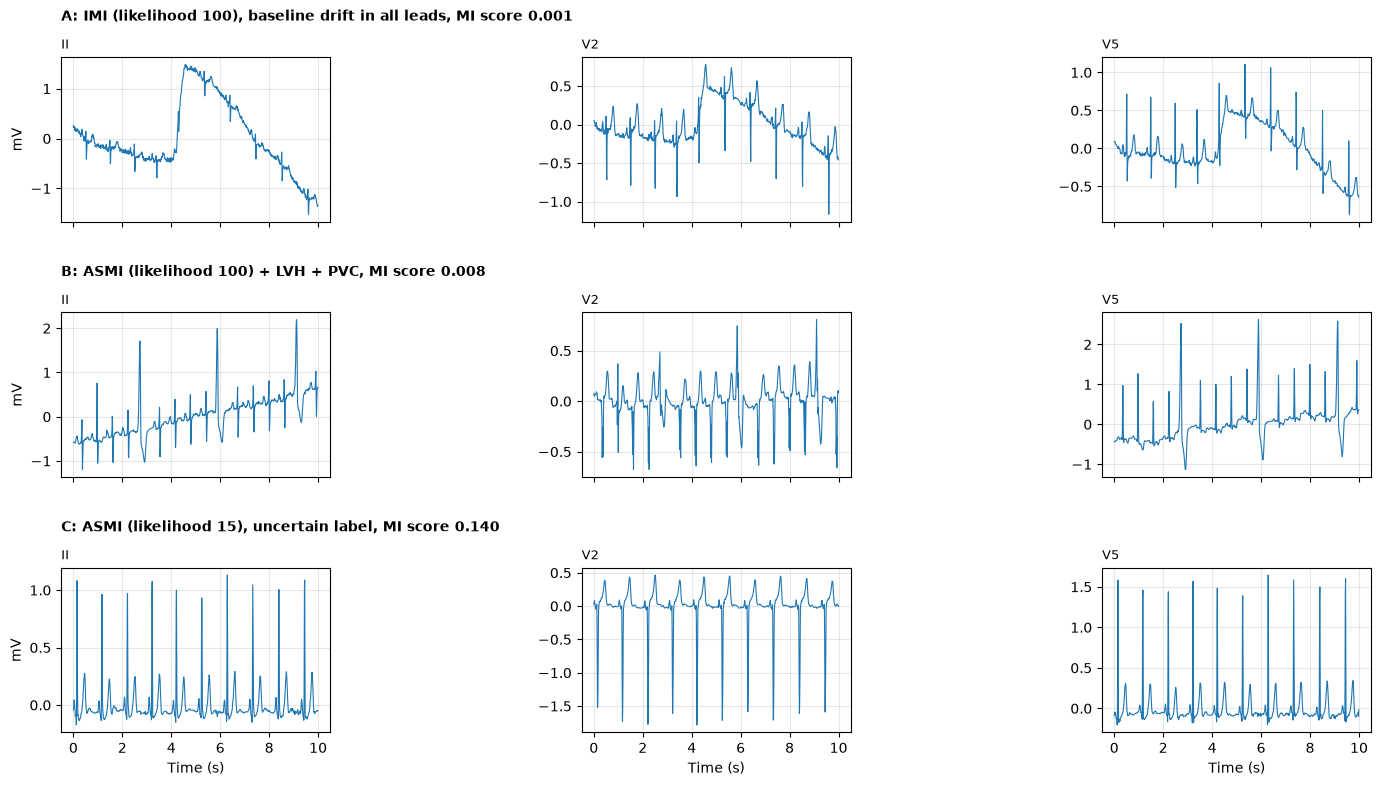

In [11]:
import matplotlib.pyplot as plt
import wfdb

# Three typical missed cases: drift everywhere, MI + LVH with a
# confident label, uncertain label

examples = {
    12145: "A: IMI (likelihood 100), baseline drift in all leads",
    2810: "B: ASMI (likelihood 100) + LVH + PVC",
    20843: "C: ASMI (likelihood 15), uncertain label",
}
leads = ["II", "V2", "V5"]

fig, axes = plt.subplots(len(examples), len(leads), figsize=(14, 8), sharex=True)
for row, (ecg_id, title) in enumerate(examples.items()):
    signal, fields = wfdb.rdsamp(str(DATA_DIR / val_df.loc[ecg_id, "filename_lr"]))
    names = [name.upper() for name in fields["sig_name"]]
    time = np.arange(signal.shape[0]) / fields["fs"]
    score = mi_pos.loc[ecg_id, "y_score_mi"]
    for col, lead in enumerate(leads):
        ax = axes[row, col]
        ax.plot(time, signal[:, names.index(lead)], linewidth=0.8)
        ax.set_title(lead, fontsize=9, loc="left")
        ax.grid(alpha=0.3)
    axes[row, 0].set_ylabel("mV")
    axes[row, 0].annotate(
        f"{title}, MI score {score:.3f}",
        xy=(0, 1.22),
        xycoords="axes fraction",
        fontweight="bold",
    )
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
fig.tight_layout(h_pad=2.5)
fig.savefig(REPORT_DIR / "missed_mi_examples.png", dpi=120)
plt.show()

## Findings

1. **Baseline drift:** 24 % of missed vs. 10 % of detected MI ECGs. Per-lead mean/std features are distorted by a wandering baseline. Idea for block 2: high-pass filter before feature extraction.
2. **Anterior and lateral infarcts** are missed more often; their signs are localised in specific leads, which per-lead summary features cannot capture. Idea: CNN on the raw signal.
3. **Uncertain labels and masking conditions:** half of the 20 worst misses have an MI likelihood of only 15 or 50; LVH and bundle branch blocks can mask infarct signs. Idea: evaluate on likelihood-100 labels only.

With 54 missed ECGs these are hypotheses, not proof.